# 0 · Detection of unknown satellite signals

**Goal.** Find every *persistent* signal in the 2.4 MHz stream around 137 MHz — unmodulated carriers (zombies) and
suppressed-carrier signals (narrowband PSK, wideband OQPSK) — within 10–30 s of its appearance, at low SNR, with few
false alarms, and hand each one (time, frequency, drift, bandwidth) to a PLL stage. Millisecond bursts (VDL Mode 2/4,
ACARS-like traffic) must be ignored. Static signals (birdies, ground carriers) are *not* filtered here; the tracking
stage decides what is a satellite.

**Method in one paragraph.** One pass over the IQ produces two spectrograms. A *fine* one (18 Hz bins) is normalised
frame by frame against its local noise floor, with burst-hit frames dropped, so that only features narrower than
~1 kHz survive; carriers are then found by summing 10 s of it along every plausible Doppler slope ("de-Doppler"
integration). A *coarse* one (586 Hz bins, 1.7 ms frames) has burst frames cut out before averaging, so what remains
is the spectrum of whatever is on *continuously*; modulated signals are found as excess over a quiet-band reference at
several bandwidths. Hits from both are linked across overlapping 10 s blocks and reported once they persist.

**Data.** IQ comes from the ASSIST simulator; the four scenarios are in `scenarios/` and are rendered to `out/`
(gitignored, ~4.6 GB each) on first run. Detections are scored against ASSIST's truth files.

Contents: 1 setup · 2 the burst problem · 3 channelizer · 4 carrier detector · 5 modulated-signal detector ·
6 linking hits into detections · 7 results · 8 findings and open points.

In [1]:
import csv
import json
import subprocess
import time
from concurrent.futures import ThreadPoolExecutor
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import scipy.fft as sfft
from scipy.ndimage import uniform_filter1d

ROOT = Path.cwd()
ASSIST, SCEN, OUT = ROOT / "ASSIST", ROOT / "scenarios", ROOT / "out"
SCENARIOS = ["det_carriers", "det_modulated", "det_empty", "det_mixed"]

FS = 2_400_000          # sample rate, Hz
FC = 137.0e6            # centre frequency, Hz
plt.rcParams.update({"figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3, "image.cmap": "viridis"})

## 1 · Setup: scenarios, IQ and truth

| Scenario | Content | Used for |
|---|---|---|
| `det_carriers` | 7 steady carriers, zenith C/N0 45 … 15 dB-Hz; one keyed + tumbling; one inside the VDL-2 channel | carrier sensitivity |
| `det_modulated` | SDPSK ladder 50 … 30 dB-Hz, ORBCOMM at calibrated level, OQPSK ladder 60/52/45 dB-Hz, METEOR at calibrated level | modulated sensitivity |
| `det_empty` | terrestrial environment only, USB humps 6× more frequent than measured | false alarms |
| `det_mixed` | different seed/hour; mixed zombies, PSK (incl. 9.6 kBd), 40 kBd OQPSK, **plus** ORBCOMM gateway bursts and LoRa (to be ignored) | hold-out check |

All include the station's measured terrestrial environment (VDL ground stations and aircraft, AM voice, 15 birdies,
the 138.11 MHz carrier, USB humps). C/N0 values are ASSIST's: dB-Hz against the local noise density.

In [2]:
def render(name):
    # Render IQ (cu8) and truth for a scenario with ASSIST, unless already there. Returns the cu8 path.
    out = OUT / name
    iq = sorted(out.glob("*.cu8"))
    if not iq:
        subprocess.run(["uv", "run", "assist", "run", str(SCEN / f"{name}.yaml"), "--sink", "cu8", "-o", str(out)],
                       cwd=ASSIST, check=True, capture_output=True)
        iq = sorted(out.glob("*.cu8"))
    if not (out / "truth.csv").exists():
        subprocess.run(["uv", "run", "assist", "truth", str(SCEN / f"{name}.yaml"), "-o", str(out / "truth.csv")],
                       cwd=ASSIST, check=True, capture_output=True)
    return iq[0]


def _t(s):
    return datetime.fromisoformat(s.replace("Z", "+00:00"))


def _f(s):
    try:
        return float(s)
    except ValueError:
        return np.nan


def load_truth(name):
    # emitters: {"source/emitter": {signal, t[s], f[Hz], cn0[dB-Hz], on[0..1]}} sampled every second;
    # events: bursts (VDL, AM voice, ...) as dicts with start/end in seconds from the clock start.
    out = OUT / name
    t0 = _t(json.loads((out / "run.json").read_text())["render"]["start_utc"])
    em = {}
    with open(out / "truth.csv") as fh:
        for r in csv.DictReader(fh):
            e = em.setdefault(f"{r['source_id']}/{r['emitter_id']}", {"signal": r["signal"], "t": [], "f": [], "cn0": [], "on": []})
            e["t"].append((_t(r["t_utc"]) - t0).total_seconds())
            e["f"].append(_f(r["f_rx_hz"])); e["cn0"].append(_f(r["cn0_dbhz"])); e["on"].append(_f(r["active_fraction"]))
    for e in em.values():
        for k in ("t", "f", "cn0", "on"):
            e[k] = np.array(e[k])
        e["cn0"] = np.where(np.isfinite(e["cn0"]) & (e["on"] > 0), e["cn0"], -np.inf)
    ev = []
    with open(out / "truth.events.csv") as fh:
        for r in csv.DictReader(fh):
            ev.append({"start": (_t(r["start"]) - t0).total_seconds(), "end": (_t(r["end"]) - t0).total_seconds(),
                       "key": f"{r['source_id']}/{r['emitter_id']}", "signal": r["signal"], "f": _f(r["f_rx_hz"]), "cn0": _f(r["cn0_dbhz"])})
    return em, ev


IQ = {name: render(name) for name in SCENARIOS}
TRUTH = {name: load_truth(name) for name in SCENARIOS}
for name in SCENARIOS:
    em, ev = TRUTH[name]
    kinds = sorted({e["signal"] for e in em.values()})
    print(f"{name:14s} {IQ[name].stat().st_size / 1e9:.1f} GB   {len(em):2d} continuous emitters {kinds}   {len(ev)} burst events")

det_carriers   4.6 GB   24 continuous emitters ['cw', 'noise_band']   3997 burst events
det_modulated  4.6 GB   26 continuous emitters ['cw', 'noise_band', 'oqpsk', 'sdpsk']   3982 burst events
det_empty      4.6 GB   15 continuous emitters ['cw', 'noise_band']   4049 burst events
det_mixed      4.6 GB   26 continuous emitters ['cw', 'noise_band', 'oqpsk', 'oqpsk_burst', 'sdpsk']   4018 burst events


## 2 · The burst problem

VDL ground stations on 136.925 and 136.975 MHz send a ~21 ms burst several times a second, 20–40 dB above the noise.
Averaged over a second they look like a continuous 25 kHz wide signal, which is exactly what a naive energy detector
would report. The fix used throughout this notebook is to look at short frames and **drop the frames a burst
touches** before averaging: a burst occupies a few frames, a continuous signal occupies all of them.

The figure shows 10 s of `det_carriers` around the VDL channels, averaged plainly and with burst frames removed.
The carrier `zvdl` (136.971 MHz, inside the VDL-2 channel) is only visible in the second.

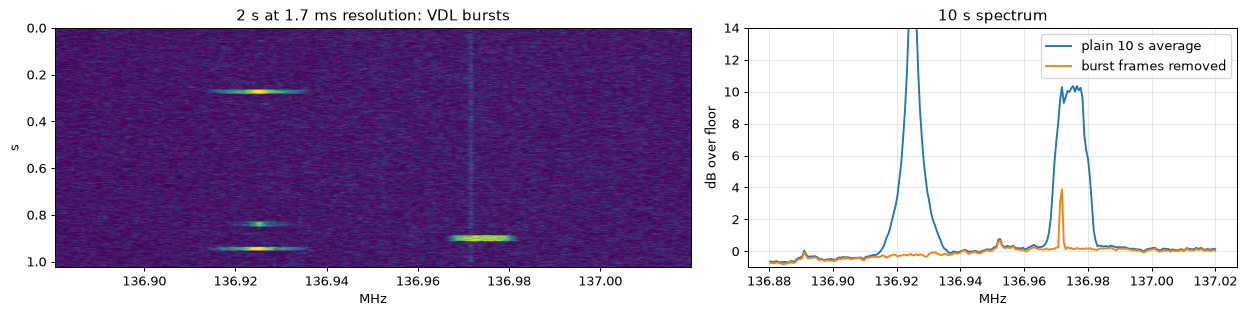

In [3]:
NC = 4096               # coarse FFT: 586 Hz bins, 1.7 ms frames
HOPC = NC // 2
CH = 16                 # coarse bins per burst-flag channel (9.4 kHz)
WINC = np.hanning(NC + 1)[:-1].astype(np.float32)
BINC = FS / NC
F_COARSE = FC + (np.arange(NC) - NC // 2) * BINC


def read_iq(mm, s0, n):
    # n complex samples starting at sample s0 of an interleaved unsigned 8-bit I/Q file
    raw = np.asarray(mm[2 * s0: 2 * (s0 + n)]).astype(np.float32)
    raw -= 127.5
    return raw.view(np.complex64)


def coarse_frames(x):
    # power spectra of half-overlapped Hann frames, [frames, NC], DC in the middle
    fr = np.lib.stride_tricks.sliding_window_view(x, NC)[::HOPC]
    X = sfft.fft(fr * WINC, axis=1)
    return sfft.fftshift(X.real**2 + X.imag**2, axes=1)


def excise_bursts(P, thr=2.0):
    # Mean spectrum over the frames of P [frames, NC] that no burst touches.
    # A (frame, 9.4 kHz channel) cell is a burst when its power exceeds `thr` x the channel's median over the frames;
    # flags are widened by one frame and one channel. Returns the mean and the fraction of frames kept per bin.
    n = P.shape[0]
    chan = P.reshape(n, NC // CH, CH).sum(2)
    flag = chan > thr * np.median(chan, axis=0)
    wide = flag.copy()
    wide[1:] |= flag[:-1]; wide[:-1] |= flag[1:]
    flag = wide.copy()
    flag[:, 1:] |= wide[:, :-1]; flag[:, :-1] |= wide[:, 1:]
    keep = np.repeat(~flag, CH, axis=1)
    cnt = keep.sum(0)
    mean = (P * keep).sum(0) / np.maximum(cnt, 1)
    mean[cnt < n // 4] = np.nan
    return mean, cnt / n


mm = np.memmap(IQ["det_carriers"], dtype=np.uint8, mode="r")
P = coarse_frames(read_iq(mm, int(480 * FS), int(10 * FS)))
plain = P.mean(0)
clean = np.nanmean([excise_bursts(P[i:i + 256])[0] for i in range(0, len(P) - 255, 256)], axis=0)
sel = (F_COARSE > 136.88e6) & (F_COARSE < 137.02e6)
ref = np.median(clean[sel])

fig, ax = plt.subplots(1, 2, figsize=(14, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
ax[0].imshow(10 * np.log10(P[:1200, sel] / ref), aspect="auto", vmin=-3, vmax=30,
             extent=[F_COARSE[sel][0] / 1e6, F_COARSE[sel][-1] / 1e6, 1200 * HOPC / FS, 0])
ax[0].set(title="2 s at 1.7 ms resolution: VDL bursts", xlabel="MHz", ylabel="s"); ax[0].grid(False)
ax[0].ticklabel_format(useOffset=False); ax[1].ticklabel_format(useOffset=False)
ax[1].plot(F_COARSE[sel] / 1e6, 10 * np.log10(plain[sel] / ref), label="plain 10 s average")
ax[1].plot(F_COARSE[sel] / 1e6, 10 * np.log10(clean[sel] / ref), label="burst frames removed")
ax[1].set(title="10 s spectrum", xlabel="MHz", ylabel="dB over floor", ylim=(-1, 14)); ax[1].legend()
plt.tight_layout()

## 3 · Channelizer

The stream is cut into **rows** of 524 288 samples (0.218 s). Each row yields:

- **fine row** (131 072 bins of 18.3 Hz). Eight half-overlapped Hann frames of 54.6 ms. Every frame is divided by its
  own local noise floor (the median of each 64-bin / 1.2 kHz block, interpolated between blocks), which flattens anything wider than ~1 kHz —
  receiver noise shape, modulated signals and bursts alike — and leaves narrow lines standing. A (frame, block) cell
  whose floor jumped to more than 1.8× the row's quiet level is a burst and is dropped. The row is the mean of the
  surviving frames, so noise has mean 1 everywhere.
- **coarse row** (4096 bins of 586 Hz). 256 half-overlapped frames of 1.7 ms, burst frames removed as in section 2,
  mean of the rest.

18 Hz was chosen because a LEO carrier at 137 MHz drifts by up to ~60–90 Hz/s: a 55 ms frame is about the longest
over which it stays inside one bin, so it is the narrowest noise bandwidth a carrier can be given without knowing its
drift. It is also the resolution of the reference waterfall (FFT 131 072).

Rows are cached in `out/<scenario>/cache/` (2.3 GB fine, 72 MB coarse per 16 min) so the detection logic can be
iterated without touching the IQ again.

In [4]:
NF = 131072             # fine FFT: 18.3 Hz bins, 54.6 ms frames
HOPF = NF // 2
ROWF = 8                # fine frames per row
ROW = ROWF * HOPF       # samples per row
TROW = ROW / FS         # 0.218 s
WB = 64                 # whitening block, fine bins (1.2 kHz)
WINF = np.hanning(NF + 1)[:-1].astype(np.float32)
BINF = FS / NF
F_FINE = FC + (np.arange(NF) - NF // 2) * BINF
BIN_IDX = np.arange(NF, dtype=np.float32)
BLOCK_CENTRE = (np.arange(NF // WB) + 0.5) * WB - 0.5


def fine_row(x, burst_thr=1.8):
    fr = np.lib.stride_tricks.sliding_window_view(x, NF)[::HOPF][:ROWF]
    X = sfft.fft(fr * WINF, axis=1)
    P = sfft.fftshift(X.real**2 + X.imag**2, axes=1).reshape(ROWF, NF // WB, WB)
    floor = np.median(P, axis=2) / np.log(2.0)            # median of exponential noise -> mean
    quiet = np.partition(floor, 1, axis=0)[1]             # second-lowest of the 8 frames
    bad = floor > burst_thr * quiet
    wide = bad.copy()
    wide[:, 1:] |= bad[:, :-1]; wide[:, :-1] |= bad[:, 1:]
    w = (~wide).astype(np.float32)
    n = w.sum(0)
    logf = np.log(floor)
    smooth_floor = np.exp(np.stack([np.interp(BIN_IDX, BLOCK_CENTRE, lf) for lf in logf]))   # [frames, NF]
    wbin = np.repeat(w, WB, axis=1)
    row = (P.reshape(ROWF, NF) / smooth_floor * wbin).sum(0) / np.maximum(np.repeat(n, WB), 1)
    row[np.repeat(n, WB) == 0] = 1.0                      # no clean frame: neutral value
    return row


def channelize(name, workers=6):
    # Fine and coarse rows of a scenario, cached. Returns (fine memmap [rows, NF], coarse array [rows, NC]).
    cache = OUT / name / "cache"
    if not (cache / "coarse.npy").exists():
        cache.mkdir(exist_ok=True)
        mm = np.memmap(IQ[name], dtype=np.uint8, mode="r")
        nrows = (mm.size // 2 - HOPF) // ROW
        fine = np.lib.format.open_memmap(cache / "fine.npy", mode="w+", dtype=np.float32, shape=(nrows, NF))
        coarse = np.zeros((nrows, NC), np.float32)

        def work(r):
            x = read_iq(mm, r * ROW, ROW + HOPF)
            fine[r] = fine_row(x)
            coarse[r] = excise_bursts(coarse_frames(x[: ROW + HOPC])[: ROW // HOPC])[0]

        t0 = time.time()
        with ThreadPoolExecutor(workers) as ex:
            list(ex.map(work, range(nrows)))
        fine.flush()
        np.save(cache / "coarse.npy", coarse)
        print(f"{name}: {nrows} rows ({nrows * TROW:.0f} s of signal) channelized in {time.time() - t0:.0f} s")
    return np.load(cache / "fine.npy", mmap_mode="r"), np.load(cache / "coarse.npy")


ROWS = {name: channelize(name) for name in SCENARIOS}

What the fine rows look like: 110 s around the 20 dB-Hz-at-zenith carrier `z20` near its closest approach, where it
is at about 15 dB-Hz and drifting at −25 Hz/s. Per pixel it is well under the noise (left). Summing the same data
along the right slope makes it obvious (right) — that is the next section.

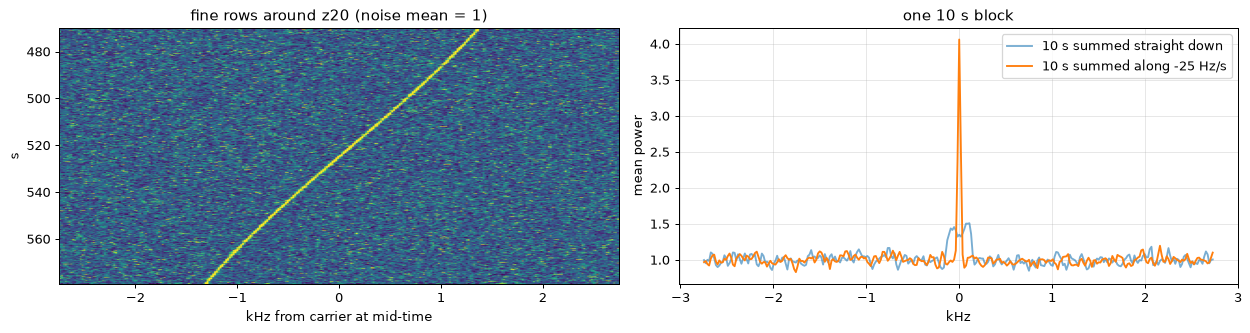

In [5]:
fine, _ = ROWS["det_carriers"]
em = TRUTH["det_carriers"][0]["z20/carrier"]
r0, nr = int(470 / TROW), 500
fmid = np.interp((r0 + nr / 2) * TROW, em["t"], em["f"])
k0 = int(round((fmid - FC) / BINF)) + NF // 2
crop = np.asarray(fine[r0:r0 + nr, k0 - 150:k0 + 150])
slope = -25.0 * TROW / BINF                               # bins per row at -25 Hz/s
k = np.arange(crop.shape[1])
aligned = np.mean([np.interp(k + slope * (r - nr / 2), k, crop[r]) for r in range(nr // 2 - 24, nr // 2 + 24)], axis=0)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ext = [-150 * BINF / 1e3, 150 * BINF / 1e3, (r0 + nr) * TROW, r0 * TROW]
ax[0].imshow(crop, aspect="auto", vmin=0.3, vmax=2.5, extent=ext); ax[0].grid(False)
ax[0].set(title="fine rows around z20 (noise mean = 1)", xlabel="kHz from carrier at mid-time", ylabel="s")
ax[1].plot((k - 150) * BINF / 1e3, crop[nr // 2 - 24: nr // 2 + 24].mean(0), label="10 s summed straight down", alpha=0.6)
ax[1].plot((k - 150) * BINF / 1e3, aligned, label="10 s summed along -25 Hz/s")
ax[1].set(title="one 10 s block", xlabel="kHz", ylabel="mean power"); ax[1].legend()
plt.tight_layout()

## 4 · Carrier detector: de-Doppler integration

Rows are grouped into **blocks** of 48 rows (10.5 s) that advance by 24 rows (5.2 s). Within a block a carrier is a
straight line in the time–frequency plane. For every frequency bin and every slope from −95 to +6 Hz/s (59 slopes,
one bin of end-to-end displacement apart — satellites only drift downward; the small positive margin covers static
signals and oscillator drift) the block is summed along that line. The result is compared with its own noise
statistics (median and MAD over frequency), giving a score *z* in standard deviations.

Four details keep false hits down:

- **Lines only.** From every line sum the mean of the bins 4–8 away on both sides (same slope) is subtracted, and a
  hit is dropped if 3 or more of those side bins are themselves above half its score. The steep spectral edges of a
  strong PSK signal are persistent and drift like a carrier, but they are plateaus, not lines.

- **Clipping.** Row values are limited to 3× the noise mean before summing. A weak carrier never reaches that, so
  sensitivity is unchanged, but a strong carrier can no longer light up every steep line that merely crosses it.
- **Persistence within the block.** The sum is kept per quarter of the block (2.6 s each). A hit needs at least 3 of
  4 quarters individually above +1σ, which removes transmissions that last only a few seconds (AM voice).
- **Peak picking.** Only the best slope per bin is kept, and only the strongest hit within ±12 bins (±220 Hz).

A hit carries the block-centre time, frequency, drift, *z*, and a C/N0 estimate from the unclipped line mean.

In [6]:
R = 48                  # rows per block (10.5 s)
HOPR = 24               # block hop (5.2 s)
NQ = 4                  # quarters per block
DRIFT_HZ_S = (-95.0, 6.0)
CLIP = 3.0


def drift_grid():
    # end-to-end line displacements in bins, 1 bin apart, ordered by |displacement| so ties go to the flattest
    lo = int(np.floor(DRIFT_HZ_S[0] * TROW / BINF * (R - 1)))
    hi = int(np.ceil(DRIFT_HZ_S[1] * TROW / BINF * (R - 1)))
    d = np.arange(lo, hi + 1)
    return d[np.argsort(np.abs(d), kind="stable")]


DISP = drift_grid()
LINE_SHIFT = np.rint(DISP[:, None] * (np.arange(R) - (R - 1) / 2) / (R - 1)).astype(int)   # [slope, row] bin shift


def dedoppler(Z):
    # Z [R, NF] -> S [NQ, slopes, NF]: per-quarter sums along each line; a line is indexed by its bin at block centre
    S = np.zeros((NQ, len(DISP), NF), np.float32)
    for i in range(len(DISP)):
        for r in range(R):
            s, q = LINE_SHIFT[i, r], r * NQ // R
            if s >= 0:
                S[q, i, :NF - s] += Z[r, s:]
            else:
                S[q, i, -s:] += Z[r, :NF + s]
    return S


def carrier_hits(Zraw, thr=6.0, q_thr=1.0, q_min=3, nms=12, max_wide=3):
    # Hits of one block of fine rows. Also returns the per-bin best score, for threshold studies.
    S = dedoppler(np.minimum(Zraw, CLIP))
    T = S.sum(0)
    T -= (17 * uniform_filter1d(T, 17, axis=1) - 7 * uniform_filter1d(T, 7, axis=1)) / 10    # minus mean of bins k+-4..8
    med = np.median(T[:, ::7], axis=1)
    sd = 1.4826 * np.median(np.abs(T[:, ::7] - med[:, None]), axis=1)
    z = (T - med[:, None]) / sd[:, None]
    zbest, ibest = z.max(0), z.argmax(0)
    hits, taken = [], np.zeros(NF, bool)
    cand = np.flatnonzero(zbest > thr)
    for k in cand[np.argsort(-zbest[cand])]:
        if taken[max(0, k - nms): k + nms + 1].any():
            continue
        taken[k] = True
        i = ibest[k]
        if k < 8 or k >= NF - 8:
            continue
        side = np.r_[k - 8: k - 3, k + 4: k + 9]
        if (z[i, side] > 0.5 * zbest[k]).sum() >= max_wide:      # not a line: a plateau or an edge
            continue
        zq = (S[:, i, k] - S[:, i, side].mean(1)) / (sd[i] / np.sqrt(NQ))
        if (zq > q_thr).sum() < q_min:
            continue
        cols = np.clip(k + LINE_SHIFT[i], 0, NF - 1)
        snr = max(float(Zraw[np.arange(R), cols].mean()) - 1.0, 1e-3)
        hits.append({"f": F_FINE[k], "drift": DISP[i] * BINF / ((R - 1) * TROW), "z": float(zbest[k]), "bw": 0.0,
                     "cn0": 10 * np.log10(snr * 1.5 * BINF)})        # 1.5 = Hann noise bandwidth in bins
    return hits, zbest


def detect_carriers(name, thr=6.0):
    # Carrier hits for every block of a scenario: list (per block) of lists of hits. Cached per threshold.
    cache = OUT / name / "cache" / f"carrier_hits_{thr:g}.json"
    if cache.exists():
        return json.loads(cache.read_text())
    fine = ROWS[name][0]
    t0, out, tail = time.time(), [], []
    for b in range(0, fine.shape[0] - R + 1, HOPR):
        hits, zbest = carrier_hits(np.asarray(fine[b:b + R]), thr)
        out.append(hits)
        tail.append(np.sort(zbest[::5])[-200:])
    np.save(OUT / name / "cache" / "carrier_ztail.npy", np.array(tail))
    cache.write_text(json.dumps(out))
    print(f"{name}: {len(out)} blocks, {sum(map(len, out))} carrier hits, {time.time() - t0:.0f} s")
    return out


def block_time(b):
    return (b * HOPR + R / 2) * TROW        # centre of block b, seconds


def block_end(b):
    return (b * HOPR + R) * TROW            # when block b is complete


CARRIER_HITS = {name: detect_carriers(name) for name in SCENARIOS}

### Sensitivity and threshold

Left: for every steady carrier in `det_carriers` and every block, was there a hit within 60 Hz of the true
frequency? Plotted against the true C/N0 of that block, pooled over the seven ladder carriers and the one inside the
VDL channel. Right: the same with the 15 birdies removed, counting hits that match *nothing* in the truth (no
satellite, birdie, AM transmission or ground carrier) in `det_empty`, per block, as a function of the threshold —
the raw false-hit rate before any linking.

P(hit) by C/N0: {1: 0.0, 3: 0.0, 5: 0.0, 7: 0.02, 9: 0.07, 11: 0.63, 13: 0.66, 15: 1.0, 17: 1.0, 19: 0.9, 21: 1.0, 23: 0.88, 25: 1.0, 27: 1.0, 29: 1.0, 31: 1.0}
unexplained hits per block at z>6: 0.15


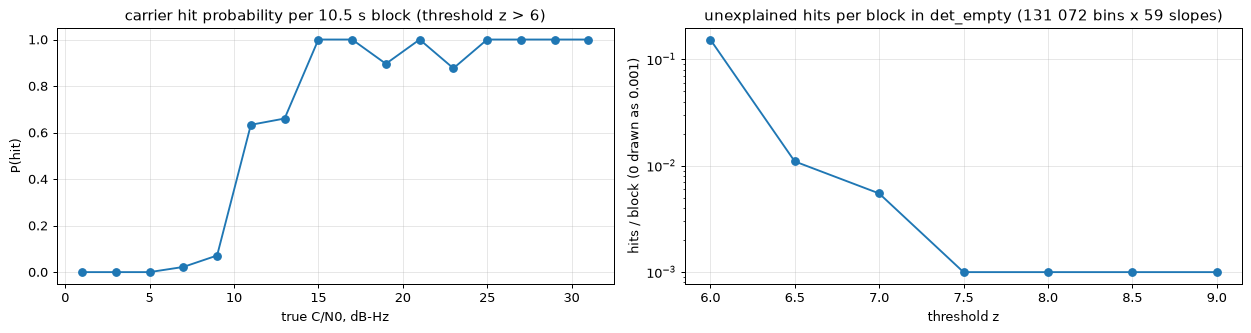

In [7]:
def emitter_at(e, t):
    # true frequency and C/N0 of an emitter at times t (C/N0 = -inf when off or below the horizon)
    cn0 = np.interp(t, e["t"], np.where(np.isfinite(e["cn0"]), e["cn0"], -99.0))
    return np.interp(t, e["t"], e["f"]), np.where(cn0 < -50, -np.inf, cn0)


def explain_hit(name, t, f, tol=150.0, widest_first=False):
    # what, if anything, in the truth is at frequency f at time t
    em, ev = TRUTH[name]
    widths = {"noise_band": 3000.0, "sdpsk": 6000.0, "oqpsk": 60000.0, "oqpsk_burst": 25000.0}
    for key, e in sorted(em.items(), key=lambda kv: widths.get(kv[1]["signal"], tol), reverse=widest_first):
        fe, cn0 = emitter_at(e, t)
        if np.isfinite(cn0) and abs(f - fe) < widths.get(e["signal"], tol):
            return key
    for v in ev:
        if v["signal"] in ("am", "cw") and v["start"] - 6 < t < v["end"] + 6 and abs(f - v["f"]) < 4000:
            return v["key"]
    return None


hits = CARRIER_HITS["det_carriers"]
tb = np.array([block_time(b) for b in range(len(hits))])
steady = [k for k in TRUTH["det_carriers"][0] if k.startswith("z") and not k.startswith("zkey")]
cn0_all, det_all = [], []
for key in steady:
    fe, cn0 = emitter_at(TRUTH["det_carriers"][0][key], tb)
    det = np.array([any(abs(h["f"] - fe[b]) < 60 for h in hits[b]) for b in range(len(hits))])
    cn0_all.append(cn0); det_all.append(det)
cn0_all, det_all = np.concatenate(cn0_all), np.concatenate(det_all)

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
edges = np.arange(0, 32, 2.0)
pd = [det_all[(cn0_all >= lo) & (cn0_all < lo + 2)].mean() for lo in edges]
ax[0].plot(edges + 1, pd, "o-")
ax[0].set(title="carrier hit probability per 10.5 s block (threshold z > 6)", xlabel="true C/N0, dB-Hz", ylabel="P(hit)")

thrs = np.arange(6.0, 9.01, 0.5)
unexplained = [h["z"] for b, hb in enumerate(CARRIER_HITS["det_empty"]) for h in hb
               if explain_hit("det_empty", block_time(b), h["f"]) is None]
rate = [np.sum(np.array(unexplained) > t) / len(CARRIER_HITS["det_empty"]) for t in thrs]
ax[1].semilogy(thrs, np.maximum(rate, 1e-3), "o-")
ax[1].set(title="unexplained hits per block in det_empty (131 072 bins x 59 slopes)", xlabel="threshold z", ylabel="hits / block (0 drawn as 0.001)")
plt.tight_layout()
print("P(hit) by C/N0:", {int(e + 1): round(float(p), 2) for e, p in zip(edges, pd) if np.isfinite(p)})
print("unexplained hits per block at z>6:", round(rate[0], 2))

## 5 · Modulated-signal detector: burst-free excess energy at several bandwidths

A suppressed-carrier signal has no line to find, only extra power across its bandwidth. The coarse rows already have
bursts removed, so:

1. **Block spectrum.** Per block (same 48 rows / 24 hop as above) take the *median over rows* of each coarse bin.
   The median discards transmissions shorter than half a block (AM voice overs) that the frame-level excision does
   not catch.
2. **Excess over a quiet reference.** Divide by a reference spectrum of the empty band and subtract the band-wide
   median (receiver gain changes). Here the reference is the median of the first 8 blocks (~45 s, before any
   satellite rises); a deployed system would keep a rolling low-percentile over the last hour instead.
3. **Matched bandwidths.** Smooth the excess with boxcars of 2.3 … 150 kHz (4 … 256 bins, in octaves) and score each
   against its noise σ measured on the reference blocks. For the three narrowest widths (≤ 9.4 kHz) the mean of two
   flanking windows is subtracted first, so slow ripples of the floor cancel.
4. **Guards.** Wider scales need the excess itself to be ≥ 4 % (0.17 dB), because the floor is only known to about
   ±1 %. Whole blocks are skipped while **USB humps** are present (a wandering comb of ±0.2–0.5 dB ripples across
   the entire band that looks like many wideband signals at once); they are recognised by at least 6 of 8 sub-bands
   having > 25 % of their bins off the reference by more than 2.5 %.
5. **Measure.** For each surviving peak the half-power width, the centroid frequency and C/N0 (integrated excess) are
   measured. Anything narrower than 3 bins (1.8 kHz) is a carrier and is left to section 4.

In [8]:
SCALES = [4, 8, 16, 32, 64, 128, 256]       # boxcar widths, coarse bins
NARROW = 16                                  # widths up to this use flanking-window subtraction
BAND = (F_COARSE >= 136.06e6) & (F_COARSE <= 138.15e6)  # below this the front-end response falls off steeply
N_REF = 8                                    # reference blocks at the start of the file


def excess_spectra(coarse):
    # block spectra relative to the quiet reference: E [blocks, NC], 0 = empty band
    nb = (coarse.shape[0] - R) // HOPR + 1
    B = np.array([np.nanmedian(coarse[b * HOPR: b * HOPR + R], axis=0) for b in range(nb)])
    E = B / np.nanmedian(B[:N_REF], axis=0) - 1
    E -= np.nanmedian(E[:, BAND], axis=1, keepdims=True)
    return np.nan_to_num(E)


def smooth(E, w):
    Ew = uniform_filter1d(E, w, axis=-1, mode="nearest")
    if w <= NARROW:
        Ew = Ew - 0.5 * (np.roll(Ew, 2 * w, axis=-1) + np.roll(Ew, -2 * w, axis=-1))
    return Ew


def hump_blocks(E, level=0.025, occupancy=0.25, nsub=8, need=6):
    # blocks during which the floor is rippled across (nearly) the whole band
    off = np.abs(uniform_filter1d(E, 32, axis=-1))[:, BAND] > level
    L = off.shape[1] // nsub
    occ = off[:, : L * nsub].reshape(len(E), nsub, L).mean(2)
    hump = (occ > occupancy).sum(1) >= need
    wide = hump.copy()
    wide[1:] |= hump[:-1]; wide[:-1] |= hump[1:]
    return wide


def measure(Eb, k, w):
    # half-power extent, centroid and C/N0 of the excess around bin k found at scale w
    Es = uniform_filter1d(Eb, max(1, w // 4), mode="nearest")
    lo, hi = max(0, k - w), min(NC, k + w + 1)
    kp = lo + int(np.argmax(Es[lo:hi]))
    a = b = kp
    while a > 0 and Es[a - 1] > 0.5 * Es[kp] and kp - a < 2 * w:
        a -= 1
    while b < NC - 1 and Es[b + 1] > 0.5 * Es[kp] and b - kp < 2 * w:
        b += 1
    seg = np.maximum(Eb[a:b + 1], 0)
    total = float(seg.sum()) or 1e-9
    return b - a + 1, float((F_COARSE[a:b + 1] * seg).sum() / total), 10 * np.log10(total * BINC)


def detect_modulated(name, thr=6.0, min_excess=0.04, min_bins=3):
    # modulated-signal hits per block, plus the excess spectra and the hump flags (for plots)
    E = excess_spectra(ROWS[name][1])
    hump = hump_blocks(E)
    Z, Ew = {}, {}
    for w in SCALES:
        Ew[w] = smooth(E, w)
        Z[w] = Ew[w] / (1.4826 * np.median(np.abs(Ew[w][:N_REF][:, BAND])) * 1.12)   # 1.12: reference is a median of 8
    out = []
    for b in range(len(E)):
        hits = []
        if not hump[b]:
            cand = []
            for w in SCALES:
                ok = (Z[w][b] > thr) & BAND
                if w > NARROW:
                    ok &= Ew[w][b] > min_excess
                cand += [(Z[w][b, k], k, w) for k in np.flatnonzero(ok)]
            occupied = np.zeros(NC, bool)
            for z, k, w in sorted(cand, reverse=True):
                lo, hi = max(0, k - w // 2), min(NC, k + w // 2 + 1)
                if occupied[lo:hi].any():
                    continue
                occupied[max(0, lo - w // 2): hi + w // 2] = True
                nbins, fc, cn0 = measure(E[b], k, w)
                if nbins >= min_bins and F_COARSE[BAND][0] <= fc <= F_COARSE[BAND][-1]:
                    hits.append({"f": fc, "drift": 0.0, "z": float(z), "bw": nbins * BINC, "cn0": cn0})
        out.append(hits)
    return out, E, hump


MOD = {name: detect_modulated(name) for name in SCENARIOS}
MOD_HITS = {name: MOD[name][0] for name in SCENARIOS}
for name in SCENARIOS:
    print(f"{name:14s} {sum(map(len, MOD_HITS[name])):4d} modulated hits, {int(MOD[name][2].sum()):3d} of {len(MOD[name][2])} blocks skipped for humps")

det_carriers      7 modulated hits,   0 of 182 blocks skipped for humps
det_modulated  1307 modulated hits,  26 of 182 blocks skipped for humps
det_empty         2 modulated hits,  75 of 182 blocks skipped for humps
det_mixed       699 modulated hits,  19 of 182 blocks skipped for humps


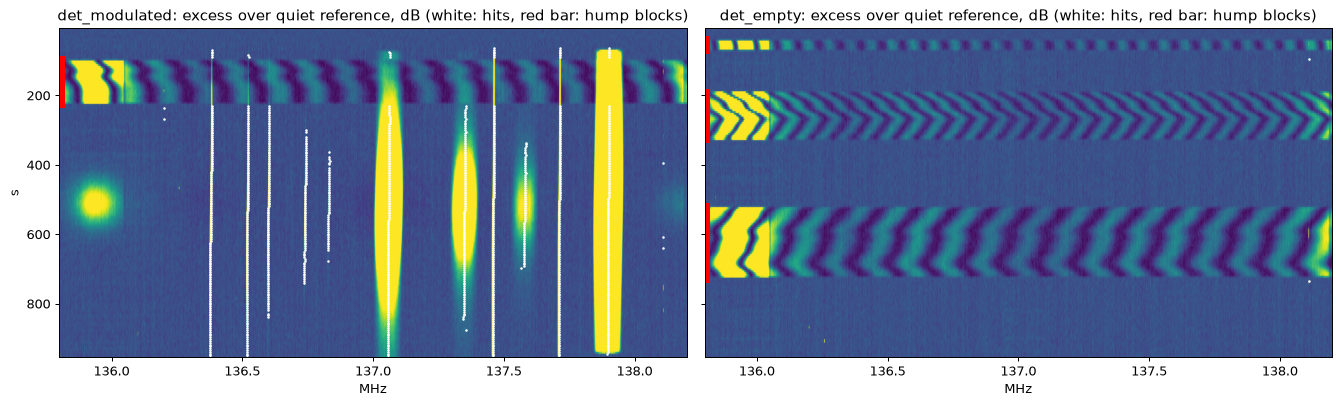

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.6), sharey=True)
for a, name in zip(ax, ["det_modulated", "det_empty"]):
    hits, E, hump = MOD[name]
    a.imshow(10 * np.log10(1 + np.clip(E, -0.5, None)), aspect="auto", vmin=-0.4, vmax=1.2,
             extent=[F_COARSE[0] / 1e6, F_COARSE[-1] / 1e6, block_time(len(E) - 1), block_time(0)])
    a.grid(False)
    for b in np.flatnonzero(hump):
        a.plot([F_COARSE[0] / 1e6 + 0.01] * 2, [block_time(b) - 2.6, block_time(b) + 2.6], color="red", lw=4)
    pts = np.array([(h["f"] / 1e6, block_time(b)) for b, hb in enumerate(hits) for h in hb]).reshape(-1, 2)
    a.plot(pts[:, 0], pts[:, 1], "w.", ms=2)
    a.set(title=f"{name}: excess over quiet reference, dB (white: hits, red bar: hump blocks)", xlabel="MHz")
ax[0].set_ylabel("s")
plt.tight_layout()

The diagonal comb in both panels is the USB-hump interference. During it the modulated-signal detector is paused
(red bar); the carrier detector is unaffected because it normalises every frame locally.

## 6 · Linking hits into detections

Hits are per block. A **detection** is declared when hits line up over consecutive blocks:

- a hit continues a track if it lies within a gate of the track's predicted frequency (carriers: last frequency +
  drift × Δt, gate 45 Hz + 10 Hz per second elapsed; modulated: within max(1.5 kHz, bandwidth/4));
- a track is **confirmed** at its 3rd hit within 4 consecutive blocks, and that moment (the end of that block) is the
  detection time handed to the PLL;
- a track ends after 2 blocks without a hit.

One cross-check between the two detectors: the steep spectral edges of a very strong PSK signal (> 50 dB-Hz) still
produce occasional weak carrier hits despite the lines-only test of section 4, so carrier hits with z < 10 that fall
inside the footprint of a modulated detection (its bandwidth plus 1.5 kHz each side) are dropped before linking. A
real residual carrier inside a modulated signal would be far above z = 10 and is kept.

Blocks overlap by half, so three hits span about 21 s of signal. A keyed transmitter produces a new detection for
each on-period; merging those into one object is the tracking stage's business.

In [10]:
def link(hits_per_block, kind, confirm=3, window=4, max_miss=2):
    # Link per-block hits into tracks. Returns confirmed tracks as dicts:
    # kind, t_detect (s), blocks, and per-hit arrays t, f, drift, bw, cn0, z.
    tracks, live = [], []
    for b, hits in enumerate(hits_per_block):
        t = block_time(b)
        claimed = set()
        for h in sorted(hits, key=lambda h: -h["z"]):
            best, best_d = None, None
            for tr in live:
                if id(tr) in claimed:
                    continue
                last, dt = tr["hits"][-1], t - block_time(tr["b"][-1])
                if kind == "carrier":
                    d, gate = abs(h["f"] - (last["f"] + last["drift"] * dt)), 45.0 + 10.0 * dt
                else:
                    d, gate = abs(h["f"] - last["f"]), max(1500.0, 0.25 * max(h["bw"], last["bw"]))
                if d < gate and (best is None or d < best_d):
                    best, best_d = tr, d
            if best is None:
                best = {"kind": kind, "b": [], "hits": [], "t_detect": None}
                live.append(best); tracks.append(best)
            best["b"].append(b); best["hits"].append(h); claimed.add(id(best))
            if best["t_detect"] is None and len(best["b"]) >= confirm and best["b"][-confirm] > b - window:
                best["t_detect"] = block_end(b)
                best["i_detect"] = len(best["b"]) - 1
        live = [tr for tr in live if b - tr["b"][-1] < max_miss + 1]
    out = []
    for tr in tracks:
        if tr["t_detect"] is None:
            continue
        rec = {"kind": kind, "t_detect": tr["t_detect"], "i_detect": tr["i_detect"], "t": np.array([block_time(b) for b in tr["b"]])}
        for k in ("f", "drift", "bw", "cn0", "z"):
            rec[k] = np.array([h[k] for h in tr["hits"]])
        out.append(rec)
    return out


def outside_modulated(hits_per_block, mod, margin=1500.0, keep_z=10.0):
    # drop weak carrier hits that fall inside the footprint of a modulated detection (its spectral edges)
    out = []
    for b, hits in enumerate(hits_per_block):
        t = block_time(b)
        spans = [(np.interp(t, d["t"], d["f"]), np.median(d["bw"]) / 2 + margin) for d in mod if d["t"][0] - 6 <= t <= d["t"][-1] + 6]
        out.append([h for h in hits if h["z"] >= keep_z or not any(abs(h["f"] - f) < half for f, half in spans)])
    return out


def detections(name, confirm=3):
    mod = link(MOD_HITS[name], "modulated", confirm)
    return link(outside_modulated(CARRIER_HITS[name], mod), "carrier", confirm) + mod


DET = {name: detections(name) for name in SCENARIOS}
for name in SCENARIOS:
    d = DET[name]
    print(f"{name:14s} {sum(x['kind'] == 'carrier' for x in d):3d} carrier detections, {sum(x['kind'] == 'modulated' for x in d):3d} modulated")

det_carriers    37 carrier detections,   0 modulated
det_modulated   23 carrier detections,  16 modulated
det_empty       24 carrier detections,   0 modulated
det_mixed       31 carrier detections,   9 modulated


## 7 · Results

Every detection is compared with the truth at its own times and frequencies and put into one of these classes:

| Class | Meaning |
|---|---|
| **satellite** | matches a satellite emitter — what we are looking for |
| **birdie** | a receiver spur (static line). Reported on purpose; the tracking stage rejects zero-Doppler signals |
| **ground** | a ground transmission that really was on for tens of seconds (long AM voice over, the 138.11 MHz carrier) |
| **ignored-type** | a signal type the detector was asked to ignore (ORBCOMM gateway bursts, LoRa) |
| **false** | nothing in the truth explains it |

In [11]:
SAT_SIGNALS = {"cw", "sdpsk", "oqpsk"}


def classify(name, d):
    # (class, truth key) of a detection: the truth entry that explains most of its hits
    em, _ = TRUTH[name]
    votes = {}
    for t, f in zip(d["t"], d["f"]):
        key = explain_hit(name, t, f, widest_first=d["kind"] == "modulated")
        votes[key] = votes.get(key, 0) + 1
    key = max(votes, key=votes.get)
    if key is None:
        return "false", None
    src = key.split("/")[0]
    if src == "birdies":
        return "birdie", key
    if key in em and em[key]["signal"] in SAT_SIGNALS:
        return "satellite", key
    if key in em or src.startswith("m-lora"):
        return "ignored-type", key
    return "ground", key


def summarize(name):
    em, _ = TRUTH[name]
    rows, classes = [], {}
    for d in DET[name]:
        d["class"], d["key"] = classify(name, d)
        classes[d["class"]] = classes.get(d["class"], 0) + 1
    for key, e in em.items():
        if key.split("/")[0] == "birdies" or e["signal"] not in SAT_SIGNALS or not np.isfinite(e["cn0"]).any():
            continue
        want = "carrier" if e["signal"] == "cw" else "modulated"
        ds = sorted([d for d in DET[name] if d["key"] == key and d["kind"] == want], key=lambda d: d["t_detect"])
        peak = e["cn0"].max()
        if ds:
            first = ds[0]
            i = first["i_detect"]
            _, cn0_true = emitter_at(e, first["t"][i])
            covered = len({round(t, 2) for d in ds for t in d["t"]}) * HOPR * TROW
            ferr = np.median([abs(d["f"][j] - emitter_at(e, d["t"][j])[0]) for d in ds for j in range(len(d["t"]))])
            rows.append((key, e["signal"], peak, f"{first['t_detect']:6.0f}", f"{float(cn0_true):5.1f}", f"{first['cn0'][i]:5.1f}",
                         f"{first['bw'][i] / 1e3:5.1f}" if want == "modulated" else "    -", f"{ferr:7.0f}", len(ds), f"{covered:5.0f}"))
        else:
            rows.append((key, e["signal"], peak, "     -", "    -", "    -", "    -", "      -", 0, "    0"))
    print(f"\n=== {name} ===   detections by class: {classes}")
    print(f"{'emitter':22s} {'type':6s} {'peak C/N0':>9s} {'t_det s':>7s} {'C/N0 at det':>11s} {'est.':>5s} {'bw kHz':>6s} {'f err Hz':>8s} {'dets':>4s} {'tracked s':>9s}")
    for r in rows:
        print(f"{r[0]:22s} {r[1]:6s} {r[2]:9.1f} {r[3]:>7s} {r[4]:>11s} {r[5]:>5s} {r[6]:>6s} {r[7]:>8s} {r[8]:4d} {r[9]:>9s}")
    for d in DET[name]:
        if d["class"] in ("false", "ignored-type", "ground"):
            print(f"   {d['class']:12s} {d['kind']:9s} t={d['t'][0]:5.0f}-{d['t'][-1]:5.0f} s  f={np.median(d['f']) / 1e6:.4f} MHz  "
                  f"bw={np.median(d['bw']) / 1e3:.1f} kHz  z={np.median(d['z']):.1f}  {d['key'] or ''}")


for name in SCENARIOS:
    summarize(name)


=== det_carriers ===   detections by class: {'birdie': 19, 'satellite': 15, 'ground': 3}
emitter                type   peak C/N0 t_det s C/N0 at det  est. bw kHz f err Hz dets tracked s
z15/carrier            cw          15.0     456        12.8  12.6      -        4    1       204
z20/carrier            cw          19.9     362        11.4  12.1      -        5    1       357
z25/carrier            cw          25.0     273        11.0  11.2      -        4    1       535
z30/carrier            cw          28.6     126        10.1  10.4      -        4    2       765
z35/carrier            cw          26.4      89        13.8  12.2      -        5    1       839
z40/carrier            cw          39.6      84        18.8  18.1      -        5    1       891
z45/carrier            cw          40.8      84        23.7  23.3      -        6    1       891
zvdl/carrier           cw          31.9      89        13.9  13.9      -        5    1       886
zkey/carrier           cw          37


=== det_modulated ===   detections by class: {'birdie': 20, 'ground': 3, 'satellite': 16}
emitter                type   peak C/N0 t_det s C/N0 at det  est. bw kHz f err Hz dets tracked s
psk-cal/stx1           sdpsk       62.5      79        43.7  43.0    4.7      124    2       760
psk-cal/stx2           sdpsk       62.4      79        43.7  42.9    4.7      148    2       760
psk-ladder/p30         sdpsk       29.2     393        22.9  20.0    2.3      181    1       273
psk-ladder/p35         sdpsk       34.2     336        24.3  23.3    4.1      166    1       435
psk-ladder/p40         sdpsk       39.2     246        24.7  23.9    4.1      199    1       608
psk-ladder/p45         sdpsk       44.2     246        29.7  29.0    4.7      178    1       729
psk-ladder/p50         sdpsk       49.2      84        28.7  28.0    4.7      191    2       755
wide-cal/lrpt          oqpsk       66.5      79        50.6  49.6   70.9      137    2       750
wide-ladder/w45        oqpsk       4


=== det_mixed ===   detections by class: {'birdie': 20, 'satellite': 18, 'ground': 2}
emitter                type   peak C/N0 t_det s C/N0 at det  est. bw kHz f err Hz dets tracked s
m-steady/carrier       cw          30.9      58        13.1  12.9      -        4    1       918
m-keyed/carrier        cw          35.2     142        11.1  13.1      -        6    4       173
m-psk-weak/a           sdpsk       33.7     288        24.7  23.5    4.1      147    1       430
m-psk-weak/b           sdpsk       37.7     273        27.9  24.1    5.3      137    2       440
m-psk/stx1             sdpsk       57.0     152        44.1  43.5    4.7      178    3       823
m-psk/stx2             sdpsk       56.9     152        44.1  43.3    4.7      122    2       823
m-weak/carrier         cw          15.1     414        10.9  10.7      -        5    1       304
m-tumble/carrier       cw          29.3     398        11.6  12.6      -        5    1       388
m-wide/w               oqpsk       51.9 

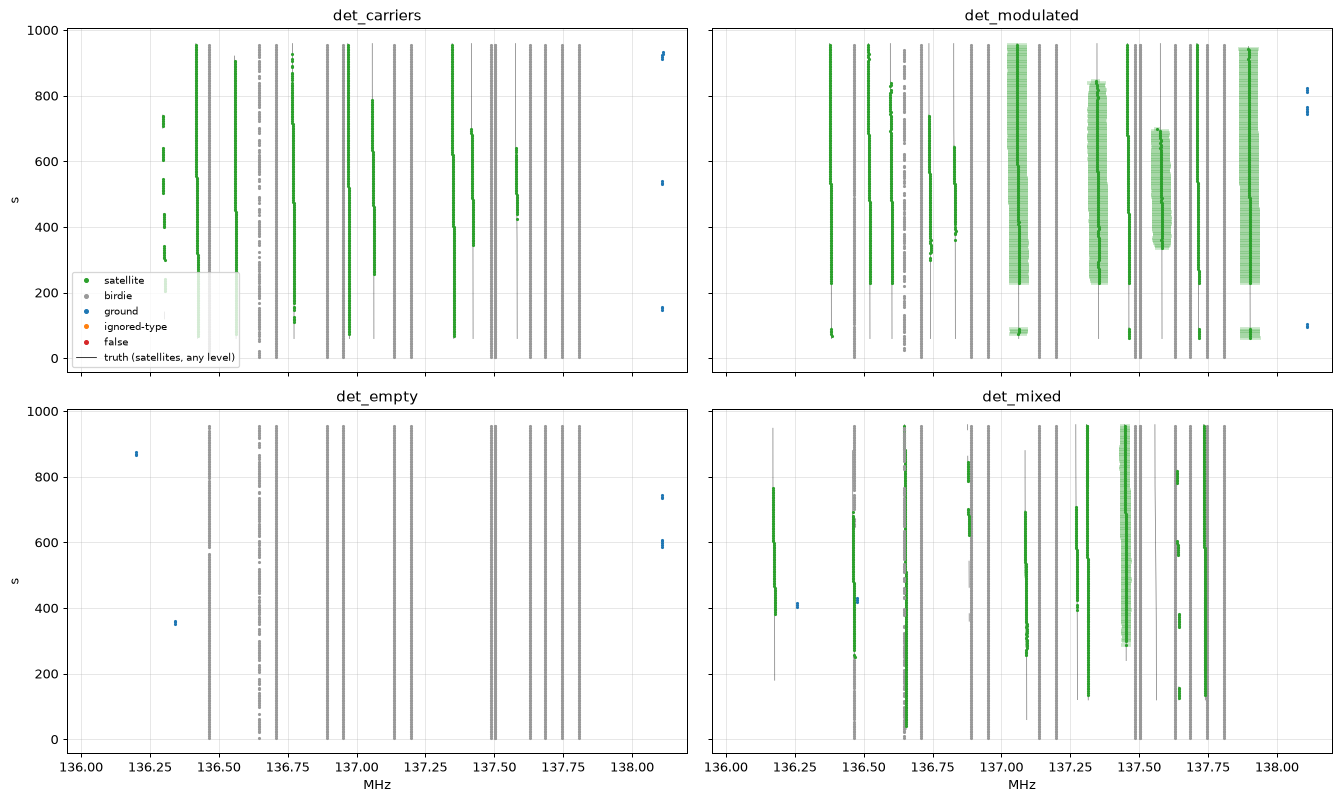

In [12]:
COLORS = {"satellite": "tab:green", "birdie": "0.6", "ground": "tab:blue", "ignored-type": "tab:orange", "false": "tab:red"}
fig, axes = plt.subplots(2, 2, figsize=(15, 9), sharex=True, sharey=True)
for ax, name in zip(axes.flat, SCENARIOS):
    em, _ = TRUTH[name]
    for key, e in em.items():
        on = np.isfinite(e["cn0"])
        if key.split("/")[0] != "birdies" and on.any():
            ax.plot(np.where(on, e["f"], np.nan) / 1e6, e["t"], color="k", lw=0.6, alpha=0.5)
    for d in DET[name]:
        if d["kind"] == "modulated":
            ax.errorbar(d["f"] / 1e6, d["t"], xerr=d["bw"] / 2e6, fmt="none", ecolor=COLORS[d["class"]], alpha=0.25, lw=3)
        ax.plot(d["f"] / 1e6, d["t"], ".", color=COLORS[d["class"]], ms=3)
    ax.set(title=name, xlim=(135.95, 138.2))
    ax.invert_yaxis()
for ax in axes[:, 0]:
    ax.set_ylabel("s")
for ax in axes[1]:
    ax.set_xlabel("MHz")
axes[0, 0].legend(handles=[plt.Line2D([], [], color=c, marker=".", ls="", label=k) for k, c in COLORS.items()]
                  + [plt.Line2D([], [], color="k", lw=0.6, label="truth (satellites, any level)")], loc="lower left", fontsize=8)
plt.tight_layout()

### Latency

Time from a signal becoming detectable to the detection being declared. Measured on the keyed zombies, whose
on-periods give clean onsets: for each on-period (true C/N0 ≥ 15 dB-Hz) the delay from key-down to the first
detection declared for that emitter.

In [13]:
def keyed_latencies(name, key, min_cn0=15.0):
    e = TRUTH[name][0][key]
    on = np.isfinite(e["cn0"]) & (e["on"] > 0.5)
    starts = e["t"][1:][on[1:] & ~on[:-1]]
    tdet = sorted(d["t_detect"] for d in DET[name] if d["key"] == key)
    out = []
    for s in starts:
        cn0 = e["cn0"][(e["t"] >= s) & (e["t"] < s + 20)]
        nxt = [t for t in tdet if t > s]
        if len(cn0) and np.median(cn0) >= min_cn0:
            out.append((s, float(np.median(cn0)), nxt[0] - s if nxt and nxt[0] - s < 60 else np.nan))
    return out


for name, key in [("det_carriers", "zkey/carrier"), ("det_mixed", "m-keyed/carrier"), ("det_mixed", "m-late/carrier")]:
    lat = keyed_latencies(name, key)
    print(f"{name}/{key}: " + ", ".join(f"on@{s:.0f}s ({c:.0f} dB-Hz) -> {l:.0f} s" for s, c, l in lat))

det_carriers/zkey/carrier: on@302s (22 dB-Hz) -> 13 s, on@402s (33 dB-Hz) -> 12 s, on@502s (30 dB-Hz) -> 17 s, on@602s (20 dB-Hz) -> 17 s
det_mixed/m-keyed/carrier: on@340s (24 dB-Hz) -> 17 s, on@560s (32 dB-Hz) -> 17 s, on@780s (18 dB-Hz) -> 17 s
det_mixed/m-late/carrier: on@623s (15 dB-Hz) -> 17 s


### Cost

Timings on this 6-core Mac (numpy/scipy, 6 threads), per 16 min of IQ:

In [14]:
mm = np.memmap(IQ["det_empty"], dtype=np.uint8, mode="r")
t0 = time.time()
for r in range(20):
    x = read_iq(mm, r * ROW, ROW + HOPF)
    fine_row(x); excise_bursts(coarse_frames(x[: ROW + HOPC])[: ROW // HOPC])
t_chan = (time.time() - t0) / 20
Z = np.asarray(ROWS["det_empty"][0][:R])
t0 = time.time(); carrier_hits(Z); t_dd = time.time() - t0
print(f"channelizer: {t_chan * 1e3:.0f} ms per 218 ms row on one thread  -> {TROW / t_chan:.1f}x real time per core")
print(f"de-Doppler:  {t_dd:.2f} s per block, one block every {HOPR * TROW:.1f} s -> {100 * t_dd / (HOPR * TROW):.0f}% of one core")

channelizer: 77 ms per 218 ms row on one thread  -> 2.8x real time per core
de-Doppler:  0.39 s per block, one block every 5.2 s -> 7% of one core


## 8 · Findings and open points

Numbers are from the four simulated 16-minute scenarios above (64 min of IQ in total); the last one, `det_mixed`,
was not used for tuning.

**What works**

| | Result |
|---|---|
| Carriers | Every carrier found, including the keyed, tumbling and in-VDL-channel ones. First detection at 10–14 dB-Hz true C/N0 for the weak ones; a hit in every block from 15 dB-Hz up. Frequency within ~5 Hz, C/N0 estimate within ~2 dB. |
| Narrowband PSK (4.8 and 9.6 kBd) | All found; first detection at 23–30 dB-Hz. Centre frequency within ~120–200 Hz, bandwidth 4–5 kHz reported for 4.8 kBd. |
| Wideband OQPSK (40 and 72 kBd) | All found; first detection at 35–39 dB-Hz. Centre within ~150–400 Hz. |
| Latency | 12–17 s from key-down to detection on the keyed zombies; ~19 s after a strong signal rises. |
| False detections | None in any scenario. VDL-2/4, ORBCOMM gateway bursts and LoRa produced no detections. |
| Reported but not satellites (by design) | The 15 birdies, and 2–4 ground transmissions per scenario that really lasted ~10 s or more (AM voice overs, the 138.11 MHz carrier). |
| Cost | Channelizer ~3× real time per core here in numpy; de-Doppler search under 10 % of a core. |

**What I have not verified**

- **Real recordings.** Everything is against ASSIST. Real spurs that drift, oscillator phase noise, gain steps and
  interference types the simulator does not model are untested.
- **Your "visible on a 131 072-point waterfall" criterion.** At 10 dB-Hz a carrier is about 1.5σ per pixel in a
  1 row/s waterfall of that size, which should be a faint but traceable line, so the carrier detector is probably
  near the visual limit. I have not compared the two side by side, and not at all for modulated signals.
- **False-alarm rate.** "Zero in 64 minutes" is all that can be said; a rate per day needs hours of data. The raw
  carrier false-hit rate is ~0.15 per block at z > 6 and falls to none seen at z > 7.5; linking three blocks is
  what brings it to zero.
- **Two dips in the hit-probability curve** (0.9 at 19 and 23 dB-Hz) were not investigated.

**Known weaknesses**

1. **Quiet reference for the modulated detector.** It is the first 45 s of each file. A deployed version needs a
   rolling reference (e.g. a low percentile per bin over the last hour) and that has not been built or tested.
   A signal already present during the reference period would be invisible.
2. **USB humps pause modulated detection.** While the comb is present, no new modulated signal is declared (existing
   tracks resume afterwards). At the measured 2 episodes/h that is a few percent of the time; in these scenarios,
   where humps were made more frequent, it was 10–40 %. The hump recogniser is tuned to the simulator's hump model.
3. **Modulated sensitivity is limited by how well the floor is known**, not by integration: wide signals need
   ≥ 4 % excess. That is why 72 kBd needs ~35 dB-Hz while a carrier needs ~12.
4. **A gap between the two detectors.** Signals roughly 0.3–1.8 kHz wide (slow telemetry, e.g. 1200 Bd) are too
   wide for the carrier path, which flattens anything broader than ~1 kHz, and too narrow for the modulated path,
   which requires 3 coarse bins. Not tested; expect reduced sensitivity there.
5. **Band edge.** The modulated detector covers 136.06–138.15 MHz. Below that the front-end response drops 12 dB
   and strong in-band signals produced a spurious rise there.
6. **Keyed transmitters give one detection per on-period**, and a pass can split into 2–3 detections when hits are
   missed for more than 10 s. Merging is left to tracking.
7. **Search limits.** Drift −95 … +6 Hz/s; anything faster (very low orbits) is lost.

**Suggested next steps**

- Run it on a few hours of real IQ and compare against the waterfall by eye; this settles the sensitivity target
  and the real false-alarm rate, and will show which of the weaknesses above matter in practice.
- Replace the fixed quiet reference by a rolling one.
- For suppressed-carrier signals, try squaring the signal in each occupied channel: BPSK/SDPSK/OQPSK then show
  spectral lines at twice the carrier (± half the symbol rate) that the *carrier* detector can find. That would be
  independent of the noise floor and of humps, would close most of the sensitivity gap in point 3, and gives the PLL
  stage a carrier to lock to rather than a band centre.
- `1_tracking`: PLL hand-off using (time, frequency, drift) of each detection, zero-Doppler rejection of birdies and
  ground carriers, merging of repeated detections.